### 1. Import Essential Libraries

**What we do:** We import the core third-party libraries needed for file manipulation, data structure handling, mathematical operations, data visualization, and deep learning framework operations.

**Why we do it:** This step establishes our programming environment. Libraries like `pandas` and `numpy` handle data structures, `matplotlib` creates our visualizations, and `keras` provides high-level APIs to construct and train our neural networks.

**How it works:**
* `os` and `urllib.request` allow file system access and downloads.
* `pandas` manages the tabular dataset representation.
* `keras` and `tensorflow` act as our backends for artificial neural network compilation and optimization.

In [1]:
import os
import zipfile
import urllib.request
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split

### 2. Set Random Seed and Check Environment Configurations

**What we do:** We initialize Keras's global random seed generator to ensure reproducibility and output the active Keras and backend configurations.

**Why we do it:** Setting a random seed ensures that any randomly initialized weights, shuffles, or splits yield the exact same results across different execution runs. We print the system versioning to verify compatibility and confirm whether we are executing on a TensorFlow or alternative engine backend.

**How it works:** We utilize `keras.utils.set_random_seed(42)` which configures Python, NumPy, and TensorFlow seed engines simultaneously.

In [2]:
keras.utils.set_random_seed(42)
import warnings
warnings.filterwarnings("ignore")

print(f"Keras Version: {keras.__version__}")
print(f"Backend Framework: {keras.backend.backend()}")

Keras Version: 3.13.2
Backend Framework: tensorflow


### 3. Retrieve and Parse the Sign Language MNIST Dataset

**What we do:** We automatically download the raw Sign Language MNIST dataset using `kagglehub` and parse the CSV tables into pixel arrays (`x_train`, `x_test`) and numerical label arrays (`y_train`, `y_test`).

**Why we do it:** The model requires access to structured image representations. Since the original Kaggle structure maps each image flatly into a single row of 784 features, we must reshape these samples into visual $28 \times 28$ image matrices.

**How it works:** We read the datasets using `pd.read_csv()`, split the dependent label column from the feature columns, and apply `.reshape(-1, 28, 28)` to transform the flat arrays into spatial dimensions.

In [3]:
import pandas as pd
import numpy as np
import os
import kagglehub

def load_sign_mnist():
    # Download the Sign Language MNIST dataset from Kaggle
    path = kagglehub.dataset_download('datamunge/sign-language-mnist')

    train_path = os.path.join(path, 'sign_mnist_train', 'sign_mnist_train.csv')
    test_path = os.path.join(path, 'sign_mnist_test', 'sign_mnist_test.csv')

    # Fallback to direct search if directory structure differs
    if not os.path.exists(train_path):
        for root, dirs, files in os.walk(path):
            for file in files:
                if file == 'sign_mnist_train.csv':
                    train_path = os.path.join(root, file)
                elif file == 'sign_mnist_test.csv':
                    test_path = os.path.join(root, file)

    train = pd.read_csv(train_path)
    test = pd.read_csv(test_path)

    y_train = train['label'].values
    x_train = train.drop('label', axis=1).values

    y_test = test['label'].values
    x_test = test.drop('label', axis=1).values

    # Convert 784 pixels → 28 × 28 images
    x_train = x_train.reshape(-1, 28, 28)
    x_test = x_test.reshape(-1, 28, 28)

    return (x_train, y_train), (x_test, y_test)

(x_train, y_train), (x_test, y_test) = load_sign_mnist()

print("=== Dataset Shapes ===")
print(f"Training images:   {x_train.shape}")
print(f"Training labels:   {y_train.shape}")
print(f"Test images:       {x_test.shape}")
print(f"Test labels:       {y_test.shape}")

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
=== Dataset Shapes ===
Training images:   (27455, 28, 28)
Training labels:   (27455,)
Test images:       (7172, 28, 28)
Test labels:       (7172,)


### 4. Basic Data Inspection and Sample Visualization

**What we do:** We check the dataset's primitive properties, print the unique labels, identify the pixel ranges, and plot the very first sample from our training set as a grayscale image.

**Why we do it:** Before transforming the data or building models, we need to inspect the inputs. This helps us ensure that the pixel values are valid, confirm which labels are present, and verify that the reshaping step correctly preserved the structural integrity of the hand gesture image.

**Expected outcome:** We display a $28 \times 28$ image depicting a specific sign language gesture alongside its integer classification target.

Training dtype: int64
Training pixel range: 0 to 255
Unique labels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
Number of classes: 24


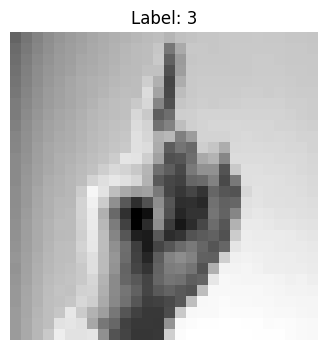

In [4]:
print("Training dtype:", x_train.dtype)
print("Training pixel range:", x_train.min(), "to", x_train.max())
print("Unique labels:", np.unique(y_train))
print("Number of classes:", len(np.unique(y_train)))

plt.figure(figsize=(4, 4))
plt.imshow(x_train[0].squeeze(), cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

### 5. Normalize Pixel Values

**What we do:** We convert our pixel array values from integers to `float32` variables and normalize them down to a scaling range between $[0.0, 1.0]$.

**Why we do it:** Neural networks converge significantly faster and remain more numerically stable when gradients are computed over small, scaled inputs rather than large integers (0 to 255).

**How it works:** We explicitly cast the arrays using `.astype("float32")` and divide the entire array by the maximum pixel value (`255.0`).

In [5]:
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0

print(x_train.dtype)
#new min and max
print(x_train.min())
print(x_train.max())

float32
0.0
1.0


### 6. Shape Expansion (Adding Channel Dimensions)

**What we do:** We expand the dimensions of our training and testing inputs to explicitly contain a single color channel.

**Why we do it:** Convolutional layers (`Conv2D`) in Keras expect input tensors to have 4 dimensions: `(batch_size, height, width, channels)`. Even though grayscale images only have one channel, we must explicitly declare it.

**How it works:** We use `np.newaxis` to expand the rightmost dimension, turning our shape from `(N, 28, 28)` into `(N, 28, 28, 1)`.

In [6]:
x_train=x_train[...,np.newaxis]
x_test=x_test[...,np.newaxis]

print(x_train.shape)
print(x_test.shape)

(27455, 28, 28, 1)
(7172, 28, 28, 1)


### 7. Categorical Label Indexing and Mapping

**What we do:** We generate lookups that map our original, non-contiguous sign language labels to a continuous series of class indices ranging from $0$ to $23$.

**Why we do it:** In the Sign Language MNIST dataset, letters 'J' (label 9) and 'Z' (label 25) are excluded because they require motion. Since some integers are skipped, we map the remaining 24 labels to consecutive integers so we can train using standard cross-entropy loss functions.

**Expected outcome:** Two dictionary mapping references: `label_to_index` and `index_to_label`.

In [7]:
# Map original labels to 24 consecutive class indices
original_labels = sorted(np.unique(y_train).tolist())

label_to_index = {
    label: index
    for index, label in enumerate(original_labels)
}

index_to_label = {
    index: label
    for label, index in label_to_index.items()
}

### 8. Apply Categorical Label Encoding

**What we do:** We apply our mapped lookups to the raw target labels (`y_train` and `y_test`), producing new continuous index targets.

**Why we do it:** This maps our target arrays directly to the continuous class indices we created, preparing them for compatibility with the final 24-unit output layer of our neural networks.

**How it works:** A list comprehension iterates over our raw targets, looks up each label's consecutive index, and wraps them in a NumPy array of 64-bit integers.

In [8]:
# Convert original labels to class indices 0–23
y_train_encoded = np.array(
    [label_to_index[label] for label in y_train],
    dtype=np.int64
)

y_test_encoded = np.array(
    [label_to_index[label] for label in y_test],
    dtype=np.int64
)

### 9. Create Training and Validation Splits

**What we do:** We split our training dataset to carve out $15\%$ of the samples for validation.

**Why we do it:** To monitor overfitting and evaluate generalization progress during training, we set aside a validation partition that the model never directly learns from. Using stratified splitting ensures that all 24 classes are represented in identical proportions across both sets.

**How it works:** We utilize scikit-learn's `train_test_split` with `stratify=y_train_encoded` and a fixed random state.

In [9]:
# Split training data into training and validation sets
x_train, x_val, y_train_encoded, y_val = train_test_split(
    x_train,
    y_train_encoded,
    test_size=0.15,
    random_state=42,
    stratify=y_train_encoded
)

print("Training images:", x_train.shape)
print("Validation images:", x_val.shape)
print("Testing images:", x_test.shape)

Training images: (23336, 28, 28, 1)
Validation images: (4119, 28, 28, 1)
Testing images: (7172, 28, 28, 1)


### 10. Visualize Sample Images with Translated Alphabet Labels

**What we do:** We display a grid of 12 sample images from our training set, transforming their mapped numeric indices back into their corresponding uppercase English letters.

**Why we do it:** Visual inspection helps us confirm that our index-to-label mapping and alphabet conversion are operating correctly, giving us an intuitive view of the actual data our model will learn from.

**How it works:** We retrieve the original label, convert it to its alphabetical character via `string.ascii_uppercase`, and map it as the title of each subplot.

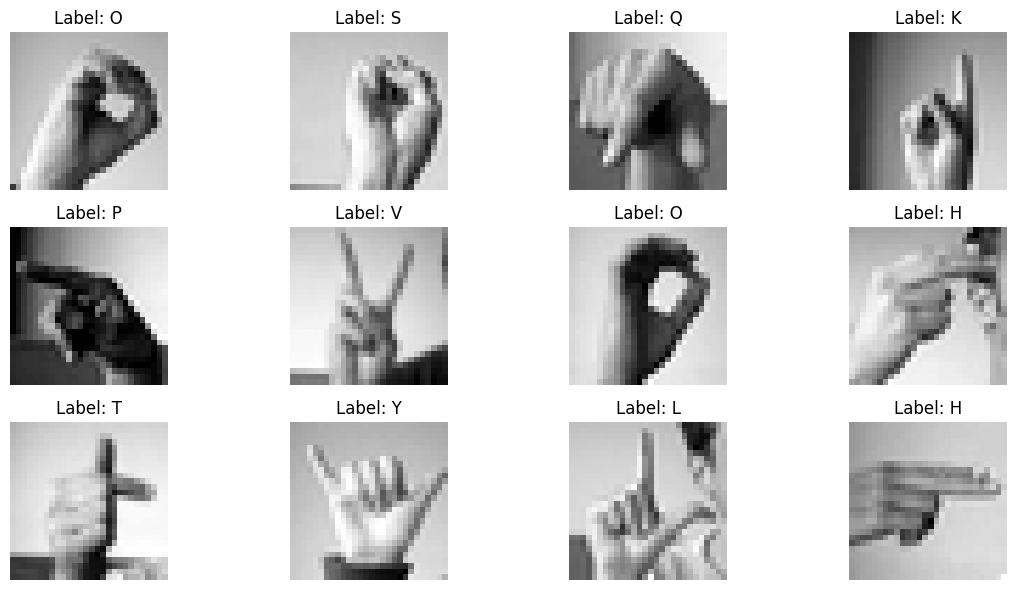

In [10]:
#Display sample images
import matplotlib.pyplot as plt
import string

plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_train[i].squeeze(), cmap="gray")

    original_label = index_to_label[y_train_encoded[i]]
    letter = string.ascii_uppercase[original_label]

    plt.title(f"Label: {letter}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 11. Define and Build the Custom Convolutional Neural Network (CNN)

**What we do:** We build a sequential convolutional neural network from scratch using Keras layers, then compile it with the Adam optimizer.

**Why we do it:** CNNs are exceptionally good at processing spatial imagery. Using small kernels, they detect local patterns like edges and textures before aggregating them into high-level features for class prediction.

**How it works:** We stack convolutional layers (`Conv2D`) to extract spatial features, max pooling layers (`MaxPooling2D`) to reduce dimensionality, a dropout layer (`Dropout`) to prevent overfitting, and dense layers for the final classification.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

model=keras.Sequential([
    keras.Input(shape=(28,28,1)),

    #First convolution block
    layers.Conv2D(16, kernel_size=(3,3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2,2)),

    #Second convolution block
    layers.Conv2D(32, kernel_size=(3,3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2,2)),


    #classification head
    layers.Flatten(),

    layers.Dense(64,activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(24,activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         1,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,624 (225.09 KB)

 Trainable params: 57,624 (225.09 KB)

 Non-trainable params: 0 (0.00 B)

### 12. Train the Custom CNN with Callbacks

**What we do:** We train our custom CNN model on the training partition for up to 20 epochs using early stopping and checkpointing callbacks.

**Why we do it:** Training fits the model's weights to our training data. Using early stopping halts training when validation loss stops improving, preventing overfitting, while model checkpointing saves the best performing weights.

**Expected outcome:** A history object containing loss and metric values for each epoch, with the final model weights saved to disk.

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "sign_language_CNN.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    x_train,
    y_train_encoded,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=callbacks
)

Epoch 1/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.3383 - loss: 2.1414 - val_accuracy: 0.7827 - val_loss: 0.8482
Epoch 2/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6809 - loss: 0.9491 - val_accuracy: 0.9269 - val_loss: 0.3801
Epoch 3/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7899 - loss: 0.6142 - val_accuracy: 0.9607 - val_loss: 0.1942
Epoch 4/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8431 - loss: 0.4528 - val_accuracy: 0.9740 - val_loss: 0.1324
Epoch 5/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8779 - loss: 0.3512 - val_accuracy: 0.9903 - val_loss: 0.0818
Epoch 6/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9033 - loss: 0.2778 - val_accuracy: 0.9937 - val_loss: 0.0485
Epoch 7/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9152 - loss: 0.2385 - val_accuracy: 0.9949 - val_loss: 0.0374
Epoch 8/20
365/365 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9313 - loss: 0.1991 - val_accuracy: 

### 13. Evaluate the Custom CNN on Unseen Test Data

**What we do:** We run our trained CNN on the held-out test dataset to compute its overall test loss and test accuracy.

**Why we do it:** The test partition contains data the model has never encountered during training or validation, making it the most reliable indicator of how well the model will generalize to new real-world inputs.

**How it works:** We call `model.evaluate()` on our normalized test features and encoded labels.

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test_encoded,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.3473
Test accuracy: 91.75%


### 14. Plot Custom CNN Training and Validation Performance

**What we do:** We generate line plots displaying the training and validation accuracy and loss over each epoch.

**Why we do it:** These curves help us visualize how well our model learned over time. They make it easy to see if the model has underfit, overfit, or reached an optimal plateau.

**Expected outcome:** Two line charts showing the validation metrics closely tracking the training metrics as the loss decreases.

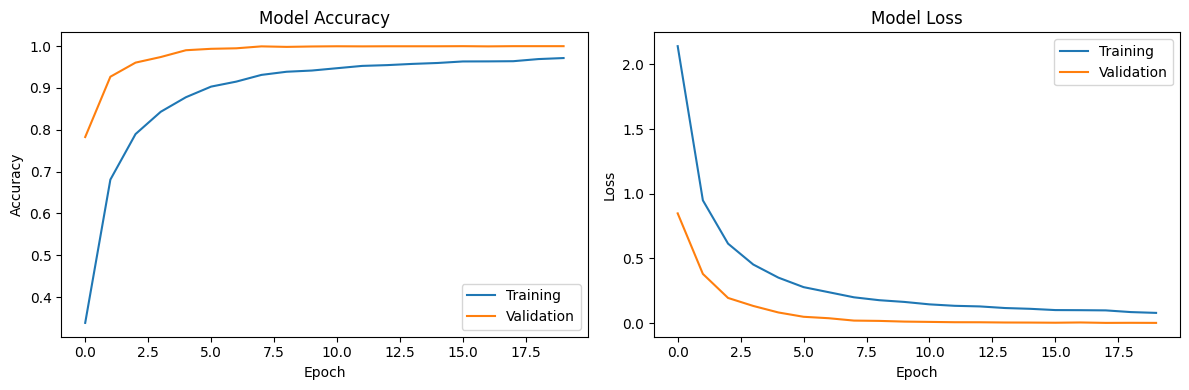

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 15. Generate Classification Report and Confusion Matrix for Custom CNN

**What we do:** We predict classes for the test dataset and generate a detailed classification report alongside a comprehensive confusion matrix heatmap.

**Why we do it:** Accuracy alone doesn't tell the whole story. A classification report breaks down performance by class (precision, recall, F1-score), while a confusion matrix highlights exactly which hand gestures are most frequently confused with one another.

**How it works:** We compute probabilities via `model.predict`, select the highest-probability class indices using `np.argmax`, and pass them to scikit-learn's evaluation functions.

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Classification Report:

              precision    recall  f1-score   support

           0     0.8874    1.0000    0.9403       331
           1     1.0000    0.9514    0.9751       432
           2     1.0000    1.0000    1.0000       310
           3     0.9608    1.0000    0.9800       245
           4     0.8878    0.9056    0.8966       498
           5     1.0000    1.0000    1.0000       247
           6     0.8946    1.0000    0.9444       348
           7     0.9368    0.9518    0.9443       436
           8     0.8628    0.8299    0.8460       288
           9     0.9966    0.8761    0.9325       331
          10     0.9127    1.0000    0.9543       209
          11     0.8841    0.8325    0.8575       394
          12     0.9947    0.6392    0.7782       291
          13     0.9856    0.8374    0.9055       246
          14     0.9971    1.0000    0.9986       347
          15     0.9535    1.0000    0.9762       164
          16    

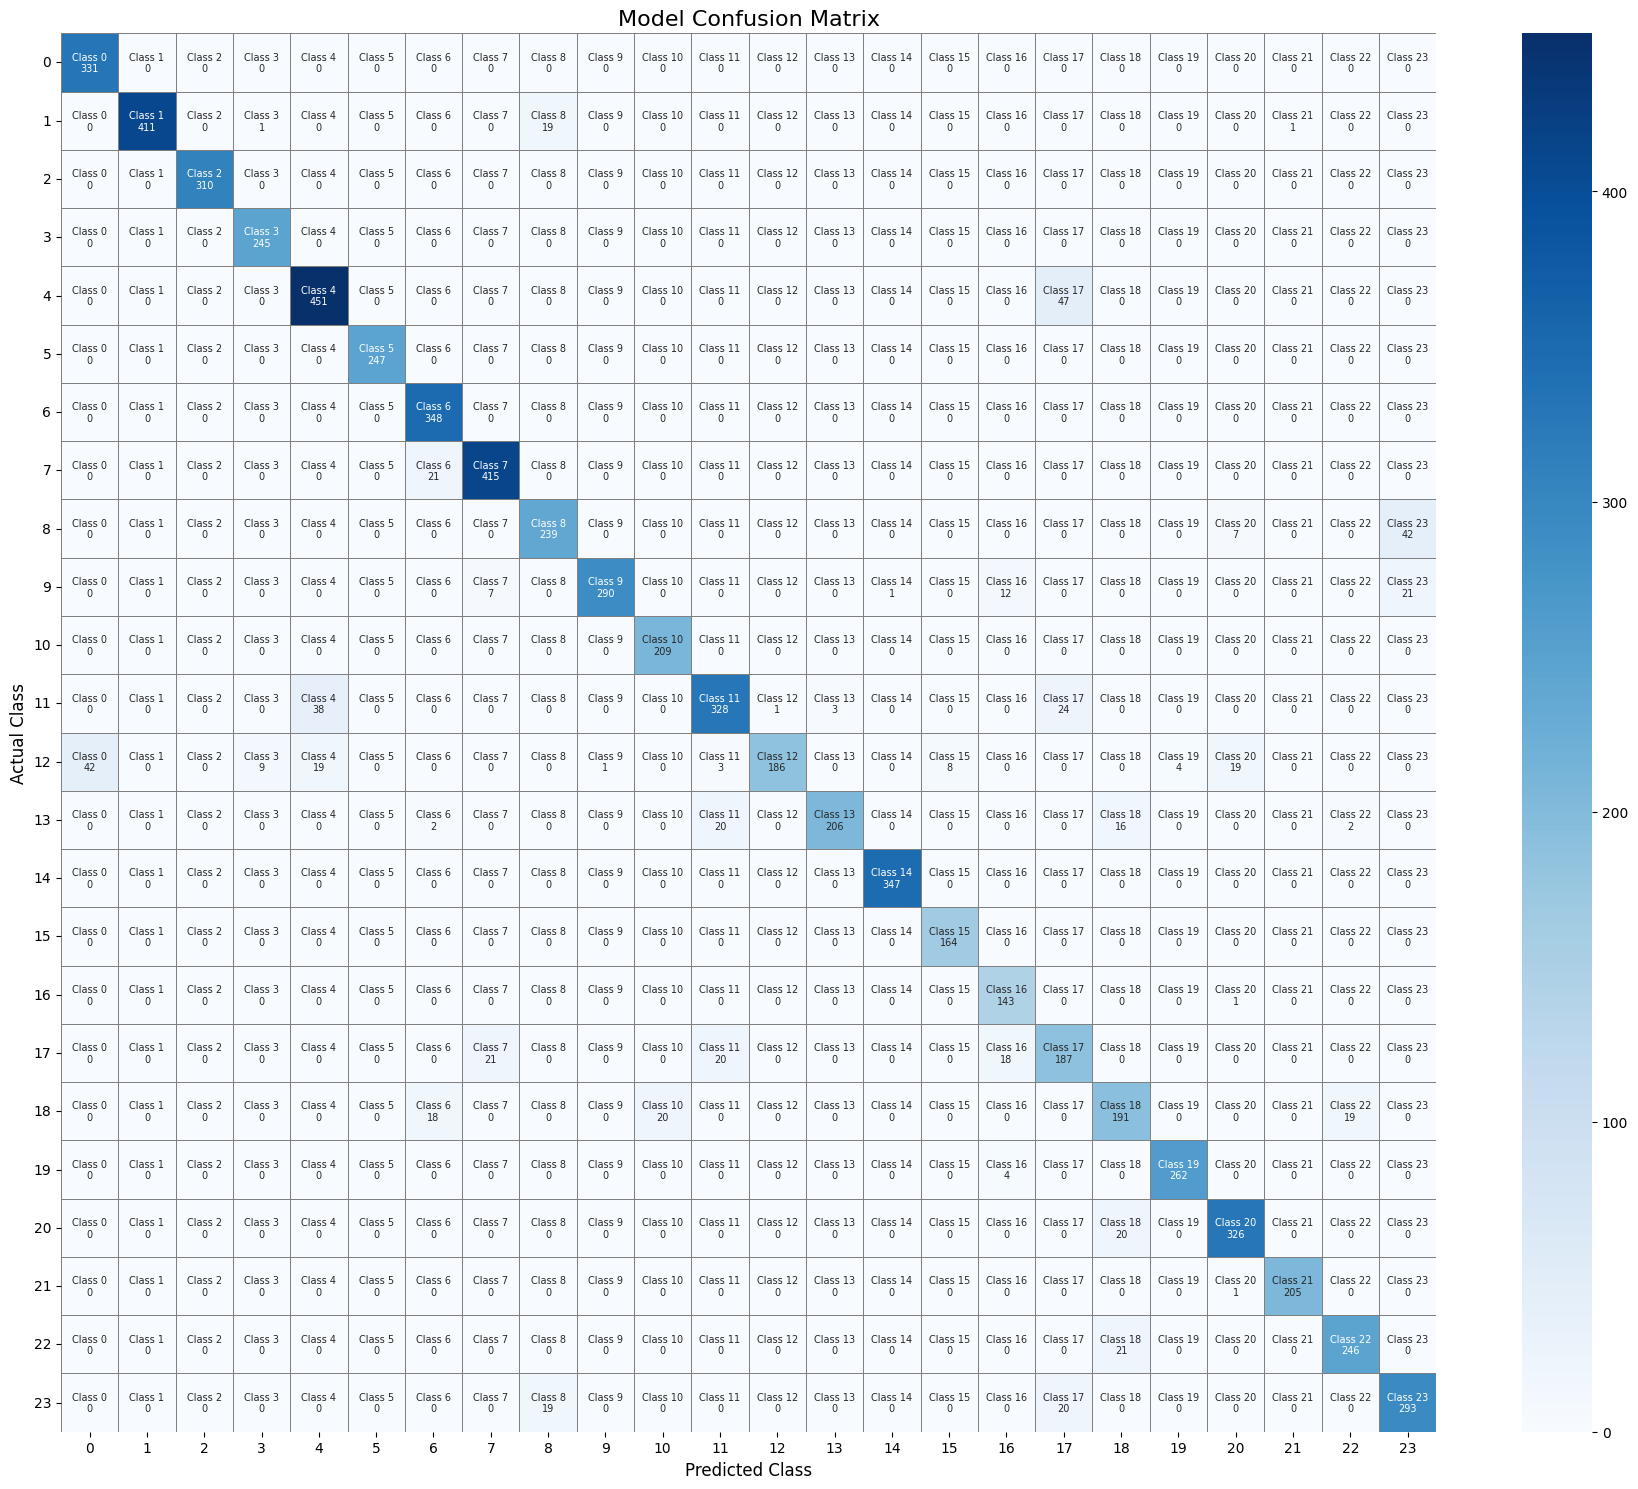

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Predictions using your trained model
y_prob = model.predict(
    x_test,
    verbose=1
)

# Convert probabilities to predicted class labels
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print("Classification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred,
    labels=np.arange(24),
    digits=4,
    zero_division=0
))

# Confusion matrix for all classes 0–23
classes = np.arange(24)

cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=classes
)

# Display predicted class and count inside each square
annotations = np.empty_like(cm, dtype=object)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annotations[i, j] = f"Class {j}\n{cm[i, j]}"

# Plot confusion matrix
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=annotations,
    fmt="",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    linewidths=0.5,
    linecolor="gray",
    annot_kws={"size": 7}
)

plt.title("Model Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 16. Save the Custom CNN Model

**What we do:** We export our trained CNN model and its configuration parameters into a single Keras format archive (`.keras`).

**Why we do it:** Saving the model preserves our trained weights, allowing us to load it later for inference or deployment without having to retrain from scratch.

**How it works:** We call `model.save()` with our target filename.

In [ ]:
model.save("model_sing_language_CNN.keras")


### 17. Test the Custom CNN with External Image Uploads

**What we do:** We set up an interactive inference pipeline where users can upload external images, pre-process them to match our training data, and run predictions using our saved CNN model.

**Why we do it:** This provides a practical, real-world way to test our model on entirely new, manually provided samples.

**How it works:** We prompt the user for an image upload, convert it to grayscale, resize it to $28 \times 28$, normalize it to $[0.0, 1.0]$, and print the model's predicted letter and confidence.

Saving sign_H.png to sign_H.png


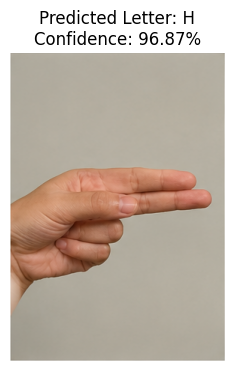

Predicted Letter: H
Confidence: 96.87%


In [ ]:

import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image

# Load scratch CNN model
model_cnn = tf.keras.models.load_model(
    "model_sing_language_CNN.keras"
)

# Sign Language MNIST labels (J and Z excluded)
labels = [i for i in range(26) if i not in (9, 25)]


def test_cnn():
    uploaded = files.upload()

    for filename in uploaded.keys():
        # Read uploaded image and convert to grayscale
        image = Image.open(filename).convert("L")
        image = np.array(image)

        # Resize to 28x28
        image = cv2.resize(image, (28, 28))

        # Normalize from [0, 255] to [0, 1]
        image = image.astype(np.float32) / 255.0

        # Add channel and batch dimensions
        image_batch = image[np.newaxis, ..., np.newaxis]

        # Predict
        predictions = model_cnn.predict(
            image_batch, verbose=0
        )[0]

        class_index = int(np.argmax(predictions))
        confidence = float(predictions[class_index]) * 100
        letter = chr(ord("A") + labels[class_index])

        # Display uploaded image and prediction
        plt.figure(figsize=(4, 4))
        plt.imshow(np.array(Image.open(filename).convert("RGB")))
        plt.title(
            f"Predicted Letter: {letter}\n"
            f"Confidence: {confidence:.2f}%"
        )
        plt.axis("off")
        plt.show()

        print("Predicted Letter:", letter)
        print(f"Confidence: {confidence:.2f}%")


# Run the test
test_cnn()


### 18. Set up Preprocessing Pipelines for MobileNetV2 Transfer Learning

**What we do:** We define preprocessing functions and build highly optimized TensorFlow datasets (`tf.data.Dataset`) to prepare our data for transfer learning with MobileNetV2.

**Why we do it:** MobileNetV2 is a deep neural network designed for larger, RGB color images. Because our dataset contains small $28 \times 28$ grayscale images, we must convert them to 3-channel RGB, scale them up to $96 \times 96$, and scale their pixel values to match MobileNetV2's expected range of $[-1, 1]$.

**How it works:** We use TensorFlow graphics operations and map them efficiently across our inputs using `tf.data` APIs.

In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = 96
BATCH_SIZE = 64

#--------Pre-processing of data for Mobilenetv2

def preprocess_image(image, label):
    # Grayscale (28, 28, 1) -> RGB (28, 28, 3)
    image = tf.image.grayscale_to_rgb(image)

    # Resize to MobileNetV2 input size
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))

    # Original pixels are already in [0, 1].
    # Convert to [-1, 1], as expected by MobileNetV2.
    image = image * 2.0 - 1.0

    return image, label


def make_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (images, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=10000,
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(
    x_train, y_train_encoded, training=True
)

val_ds = make_dataset(
    x_val, y_val
)

test_ds = make_dataset(
    x_test, y_test_encoded
)

### 19. Initialize the MobileNetV2 Backbone

**What we do:** We load the MobileNetV2 model architecture pre-trained on ImageNet, excluding its final classification head, and freeze all of its layers.

**Why we do it:** By leveraging feature representations already learned on millions of images, we can save significant training time. Freezing the layers ensures we don't destroy these pre-trained feature extractors while training our new classification head.

**How it works:** We call `keras.applications.MobileNetV2` with `include_top=False` and set `base_model.trainable = False`.

In [12]:
base_model=keras.applications.MobileNetV2(
    weights="imagenet",
    input_shape=(IMG_SIZE,IMG_SIZE,3),
    include_top=False
)


base_model.trainable=False

print("Total backbone layers:", len(base_model.layers))
print("Trainable backbone:", base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total backbone layers: 154
Trainable backbone: False


### 20. Assemble and Compile the MobileNetV2 Feature Extractor Model

**What we do:** We connect the frozen MobileNetV2 backbone to a new custom classification head, then compile the model using the Adam optimizer.

**Why we do it:** We need to adapt the general features extracted by MobileNetV2 to our specific sign language task. Our classification head will map those features directly to our 24 target classes.

**How it works:** We stack our frozen backbone inside a Keras sequential model, followed by a `GlobalAveragePooling2D` layer to compress spatial features, dropout layers to prevent overfitting, and a final dense softmax layer.

In [13]:
model_mobilenet=keras.Sequential([
    keras.Input(shape=(IMG_SIZE,IMG_SIZE,3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128,activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(24,activation="softmax")

],name="sign_language_mobilenetv2")



model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mobilenet.summary()

Model: "sign_language_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,425,048 (9.25 MB)

 Trainable params: 167,064 (652.59 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 21. Train the MobileNetV2 Feature Extractor Model

**What we do:** We train our new classification head on the training dataset using early stopping and checkpointing callbacks.

**Why we do it:** Since the backbone is frozen, this step only updates the weights of our custom classification head, allowing it to quickly learn how to categorize the extracted features.

**Expected outcome:** The model should rapidly achieve high accuracy on both our training and validation sets.

In [ ]:
callbacks=[
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    keras.callbacks.ModelCheckpoint(
        "mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]


history_mobilenet=model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 37s 57ms/step - accuracy: 0.8270 - loss: 0.5772 - val_accuracy: 0.9922 - val_loss: 0.0438
Epoch 2/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9715 - loss: 0.0962 - val_accuracy: 0.9947 - val_loss: 0.0235
Epoch 3/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9814 - loss: 0.0624 - val_accuracy: 0.9944 - val_loss: 0.0220
Epoch 4/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9874 - loss: 0.0414 - val_accuracy: 0.9983 - val_loss: 0.0063
Epoch 5/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9899 - loss: 0.0331 - val_accuracy: 0.9976 - val_loss: 0.0079
Epoch 6/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9912 - loss: 0.0288 - val_accuracy: 0.9988 - val_loss: 0.0051
Epoch 7/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9916 - loss: 0.0267 - val_accuracy: 0.9983 - val_loss: 0.0054
Epoch 8/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9916 - loss: 0.0257 - val_acc

### 22. Evaluate the MobileNetV2 Feature Extractor Model on Test Data

**What we do:** We evaluate our newly trained MobileNetV2-based model on the preprocessed test dataset.

**Why we do it:** This allows us to measure how well our transfer learning approach performs compared to the custom CNN we trained from scratch.

**How it works:** We run `model_mobilenet.evaluate()` on our test dataset generator.

In [ ]:
test_loss, test_accuracy = model_mobilenet.evaluate(
    test_ds,
    verbose=1
)

print(f"MobileNetV2 Test Loss: {test_loss:.4f}")
print(f"MobileNetV2 Test Accuracy: {test_accuracy:.2%}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 10s 87ms/step - accuracy: 0.9886 - loss: 0.0411
MobileNetV2 Test Loss: 0.0411
MobileNetV2 Test Accuracy: 98.86%


### 23. Generate Classification Report and Confusion Matrix for MobileNetV2 Feature Extractor

**What we do:** We predict classes for the test dataset using the MobileNetV2 model and plot its classification report and confusion matrix.

**Why we do it:** This helps us analyze our transfer learning model's performance in detail, showing us which classes saw the greatest improvements in precision and recall.

**How it works:** We run model predictions over our test dataset and construct our reports and seaborn heatmap visualization.

113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step
MobileNet Classification Report:

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       331
           1     0.9977    1.0000    0.9988       432
           2     1.0000    1.0000    1.0000       310
           3     0.9959    0.9878    0.9918       245
           4     0.9980    0.9819    0.9899       498
           5     0.9960    1.0000    0.9980       247
           6     0.9886    0.9971    0.9928       348
           7     1.0000    0.9931    0.9965       436
           8     1.0000    0.9861    0.9930       288
           9     0.9658    0.9396    0.9525       331
          10     1.0000    1.0000    1.0000       209
          11     0.9922    0.9670    0.9794       394
          12     0.9446    0.9966    0.9699       291
          13     1.0000    1.0000    1.0000       246
          14     0.9971    0.9971    0.9971       347
          15     0.9939    1.0000    0.9970       164
    

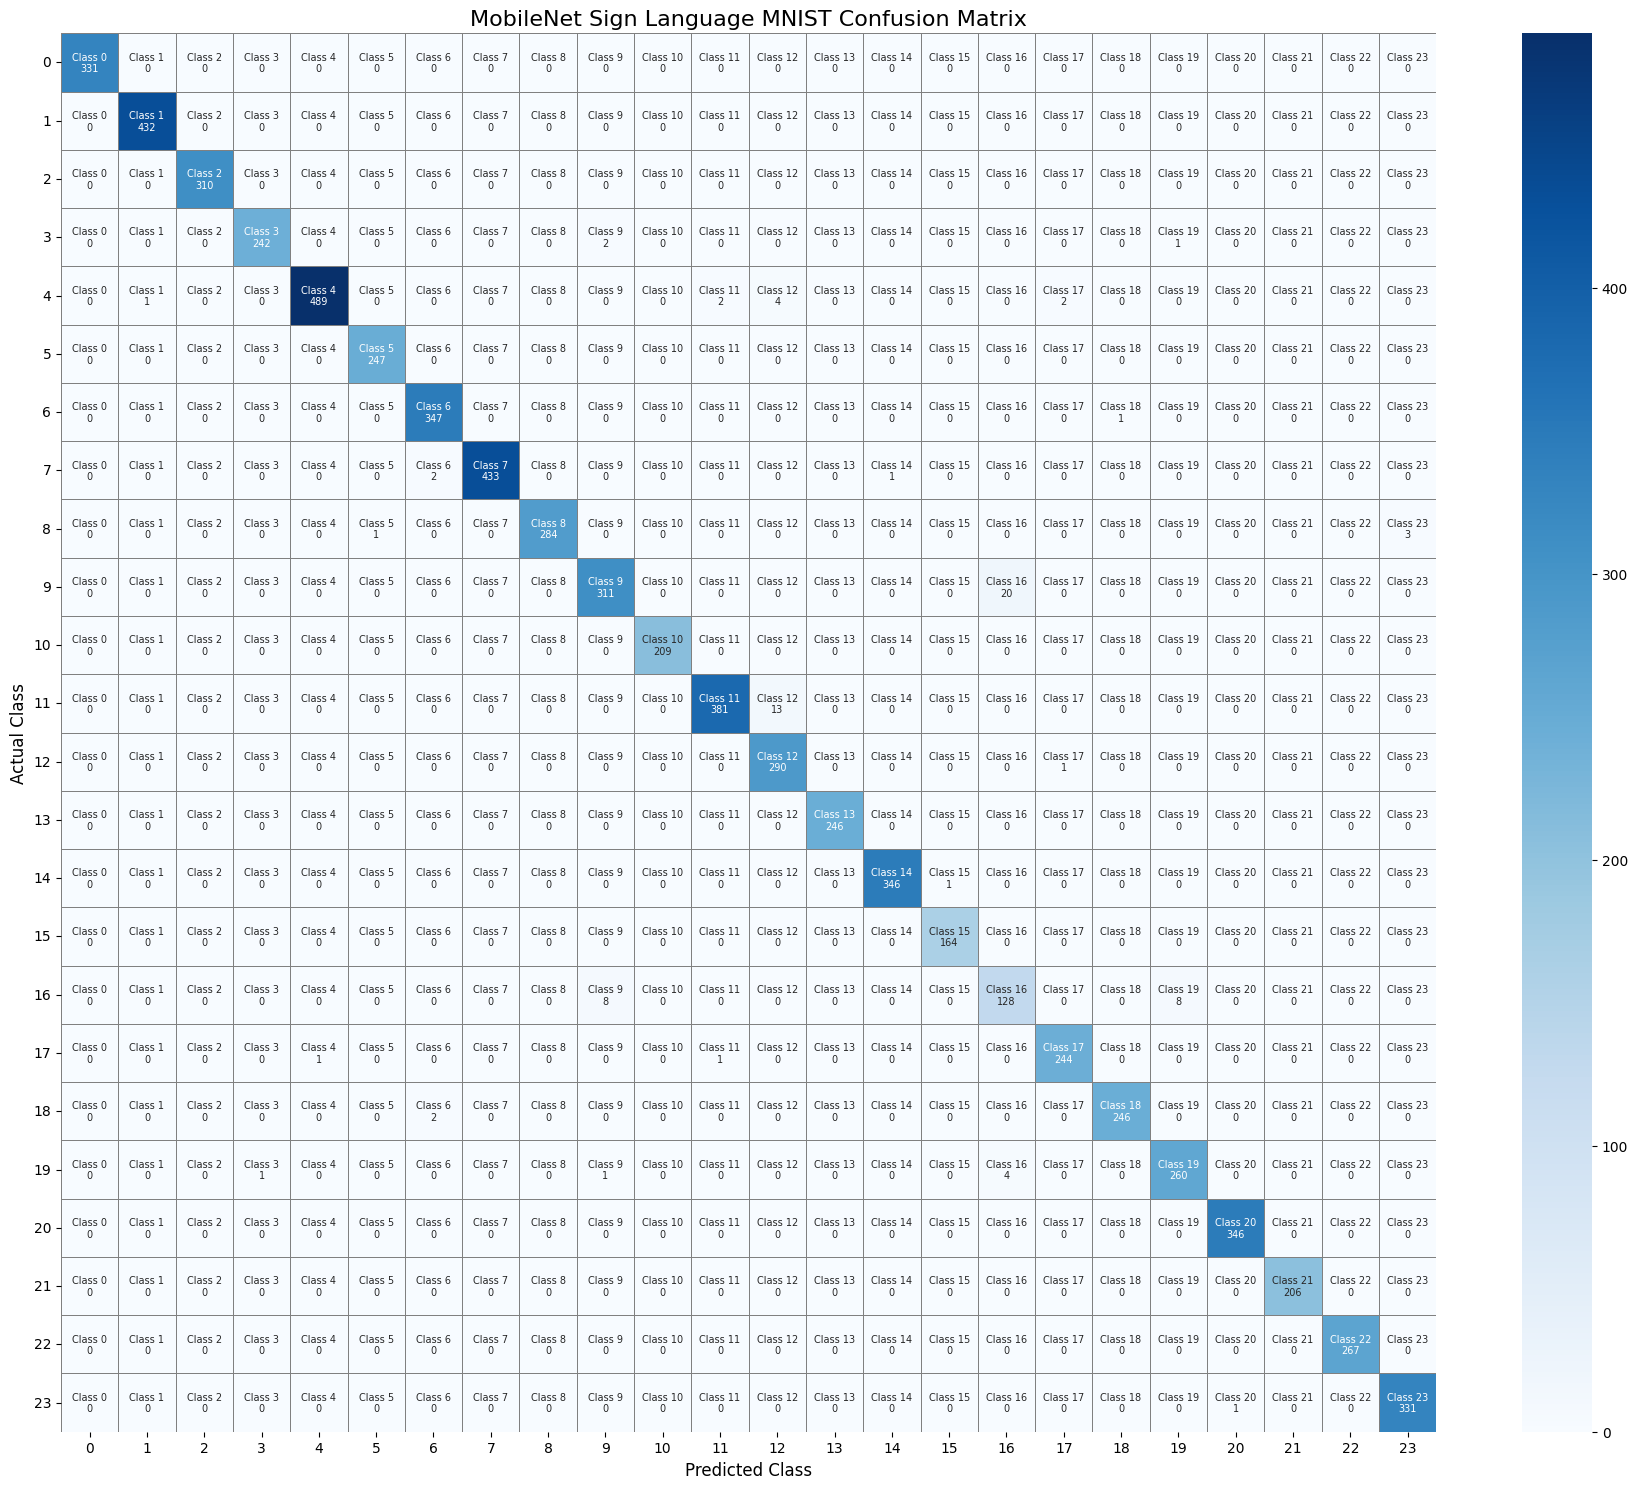

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Predictions using MobileNet
y_prob_mobilenet = model_mobilenet.predict(
    test_ds,
    verbose=1
)

y_pred_mobilenet = np.argmax(y_prob_mobilenet, axis=1)

# Classification report
print("MobileNet Classification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred_mobilenet,
    labels=np.arange(24),
    digits=4,
    zero_division=0
))

# Confusion matrix for all classes 0–23
classes = np.arange(24)

cm_mobilenet = confusion_matrix(
    y_test_encoded,
    y_pred_mobilenet,
    labels=classes
)

# Display predicted class and count inside each square
annotations = np.empty_like(cm_mobilenet, dtype=object)

for i in range(cm_mobilenet.shape[0]):
    for j in range(cm_mobilenet.shape[1]):
        annotations[i, j] = f"Class {j}\n{cm_mobilenet[i, j]}"

# Plot confusion matrix
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm_mobilenet,
    annot=annotations,
    fmt="",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    linewidths=0.5,
    linecolor="gray",
    annot_kws={"size": 7}
)

plt.title("MobileNet Sign Language MNIST Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 24. Save the MobileNetV2 Model

**What we do:** We export our trained MobileNetV2 transfer learning model as a `.keras` file.

**Why we do it:** This preserves our newly trained classification head alongside its pre-trained backbone weights for future use.

**How it works:** We call `model_mobilenet.save()` with the target filename.

In [ ]:
model_mobilenet.save("model_sing_language_mobilenetv2.keras")


### 25. Test MobileNetV2 Model on External Image Uploads

**What we do:** We set up an interactive inference pipeline for our MobileNetV2 model, allowing users to upload and classify external images.

**Why we do it:** This lets us verify how our transfer learning model handles new, real-world images, and allows us to compare its performance directly with our custom CNN.

**How it works:** The uploaded image is resized to $96 \times 96$, converted to RGB, normalized to the $[-1, 1]$ range, and run through the model for a prediction.

Saving sign_H.png to sign_H (1).png


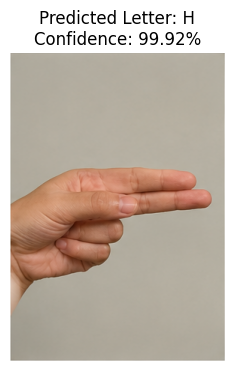

Image: sign_H (1).png
Predicted Letter: H
Confidence: 99.92%


In [ ]:

import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image

# Load MobileNetV2 model
model_mobilenet = tf.keras.models.load_model(
    "model_sing_language_mobilenetv2.keras"
)

# Sign Language MNIST labels (J and Z excluded)
labels = [i for i in range(26) if i not in (9, 25)]


def test_mobilenet():
    uploaded = files.upload()

    for filename in uploaded.keys():

        # Read uploaded image and convert to RGB
        image = Image.open(filename).convert("RGB")
        image = np.array(image)

        # Resize to 96x96
        image = cv2.resize(image, (96, 96))

        # Normalize from [0, 255] to [-1, 1]
        image = image.astype(np.float32) / 255.0
        image = (image * 2.0) - 1.0

        # Add batch dimension
        image_batch = np.expand_dims(image, axis=0)

        # Predict
        predictions = model_mobilenet.predict(
            image_batch, verbose=0
        )[0]

        class_index = int(np.argmax(predictions))
        confidence = float(predictions[class_index]) * 100
        letter = chr(ord("A") + labels[class_index])

        # Display uploaded image and prediction
        original = Image.open(filename).convert("RGB")

        plt.figure(figsize=(4, 4))
        plt.imshow(original)
        plt.title(
            f"Predicted Letter: {letter}\n"
            f"Confidence: {confidence:.2f}%"
        )
        plt.axis("off")
        plt.show()

        print("Image:", filename)
        print("Predicted Letter:", letter)
        print(f"Confidence: {confidence:.2f}%")


# Run the test
test_mobilenet()

### 26. Unfreeze the Top Layers of the MobileNetV2 Backbone for Fine-Tuning

**What we do:** We unfreeze the last 30 layers of our pre-trained MobileNetV2 backbone, keeping the earlier layers frozen.

**Why we do it:** Fine-tuning allows the deeper layers of our pre-trained backbone to adapt specifically to the unique details of our sign language dataset, often yielding a significant boost in classification accuracy.

**How it works:** We set `base_model.trainable = True`, then iterate through the backbone layers, setting `layer.trainable = False` for all but the final 30 layers.

In [14]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total backbone layers:", len(base_model.layers))
print("Trainable backbone:", base_model.trainable)

Total backbone layers: 154
Trainable backbone: True


### 27. Freeze Batch Normalization Layers

**What we do:** We iterate through our backbone layers and explicitly freeze any `BatchNormalization` layers.

**Why we do it:** Unfreezing batch normalization layers during fine-tuning on a small target dataset can destabilize training because their calculated means and variances might fluctuate wildly. Keeping them frozen ensures stable convergence.

**How it works:** We check each layer's type using `isinstance(layer, layers.BatchNormalization)` and set `layer.trainable = False`.

In [15]:
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

### 28. Compile the Fine-Tuned MobileNetV2 Model

**What we do:** We re-compile our model using a very low learning rate ($0.0001$).

**Why we do it:** When fine-tuning pre-trained weights, using a high learning rate can cause the model to forget its useful pre-trained representations. A small learning rate ensures we make only minor, incremental updates to these highly optimized layers.

**How it works:** We re-run `model_mobilenet.compile` with our adjusted learning rate.

In [16]:
model_mobilenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_mobilenet.summary()

Model: "sign_language_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,425,048 (9.25 MB)

 Trainable params: 1,677,784 (6.40 MB)

 Non-trainable params: 747,264 (2.85 MB)

### 29. Fine-Tune the MobileNetV2 Model

**What we do:** We train our model for another 10 epochs with our unfrozen backbone layers and adjusted learning rate.

**Why we do it:** This final training phase fine-tunes both our custom classification head and the top 30 layers of the backbone together, helping the model learn highly specialized features for our sign language dataset.

**Expected outcome:** The training log should show our validation loss dropping to near-zero as our accuracy reaches peak performance.

In [17]:
history_finetune=model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
     ],
    verbose=1
)


Epoch 1/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 57s 77ms/step - accuracy: 0.8380 - loss: 0.5557 - val_accuracy: 0.9947 - val_loss: 0.0153
Epoch 2/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9926 - loss: 0.0287 - val_accuracy: 0.9993 - val_loss: 0.0042
Epoch 3/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9965 - loss: 0.0112 - val_accuracy: 0.9998 - val_loss: 7.1644e-04
Epoch 4/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9959 - loss: 0.0120 - val_accuracy: 0.9951 - val_loss: 0.0150
Epoch 5/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9980 - loss: 0.0066 - val_accuracy: 0.9998 - val_loss: 2.5969e-04
Epoch 6/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.9958 - loss: 0.0150 - val_accuracy: 0.9990 - val_loss: 0.0024
Epoch 7/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.9981 - loss: 0.0065 - val_accuracy: 1.0000 - val_loss: 1.5285e-04
Epoch 8/10
365/365 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9999 - loss: 5.4

### 30. Evaluate the Fine-Tuned MobileNetV2 Model on Test Data

**What we do:** We run a final evaluation of our fine-tuned MobileNetV2 model on our test dataset.

**Why we do it:** This allows us to measure the final performance of our optimized model, giving us a clear view of how much fine-tuning improved our overall test accuracy.

**How it works:** We call `model_mobilenet.evaluate()` on our test dataset generator.

In [18]:
test_loss, test_accuracy = model_mobilenet.evaluate(
    test_ds,
    verbose=1
)

print(f"MobileNetV2 Test Loss: {test_loss:.4f}")
print(f"MobileNetV2 Test Accuracy: {test_accuracy:.2%}")

113/113 ━━━━━━━━━━━━━━━━━━━━ 11s 93ms/step - accuracy: 0.9993 - loss: 0.0016
MobileNetV2 Test Loss: 0.0016
MobileNetV2 Test Accuracy: 99.93%


### 31. Generate Classification Report and Confusion Matrix for the Fine-Tuned Model

**What we do:** We perform a final test prediction with our fine-tuned MobileNetV2 model and display its classification report and confusion matrix.

**Why we do it:** This provides a detailed breakdown of our model's final performance, helping us confirm that fine-tuning successfully resolved any remaining misclassifications across our 24 target classes.

**Expected outcome:** A highly accurate classification report with near-perfect scores across almost all gesture classes.

113/113 ━━━━━━━━━━━━━━━━━━━━ 15s 51ms/step
MobileNet Classification Report:

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       331
           1     1.0000    1.0000    1.0000       432
           2     1.0000    1.0000    1.0000       310
           3     1.0000    1.0000    1.0000       245
           4     1.0000    1.0000    1.0000       498
           5     1.0000    1.0000    1.0000       247
           6     0.9943    1.0000    0.9971       348
           7     1.0000    0.9977    0.9989       436
           8     1.0000    1.0000    1.0000       288
           9     1.0000    0.9970    0.9985       331
          10     1.0000    1.0000    1.0000       209
          11     1.0000    1.0000    1.0000       394
          12     1.0000    1.0000    1.0000       291
          13     1.0000    1.0000    1.0000       246
          14     1.0000    1.0000    1.0000       347
          15     1.0000    1.0000    1.0000       164
    

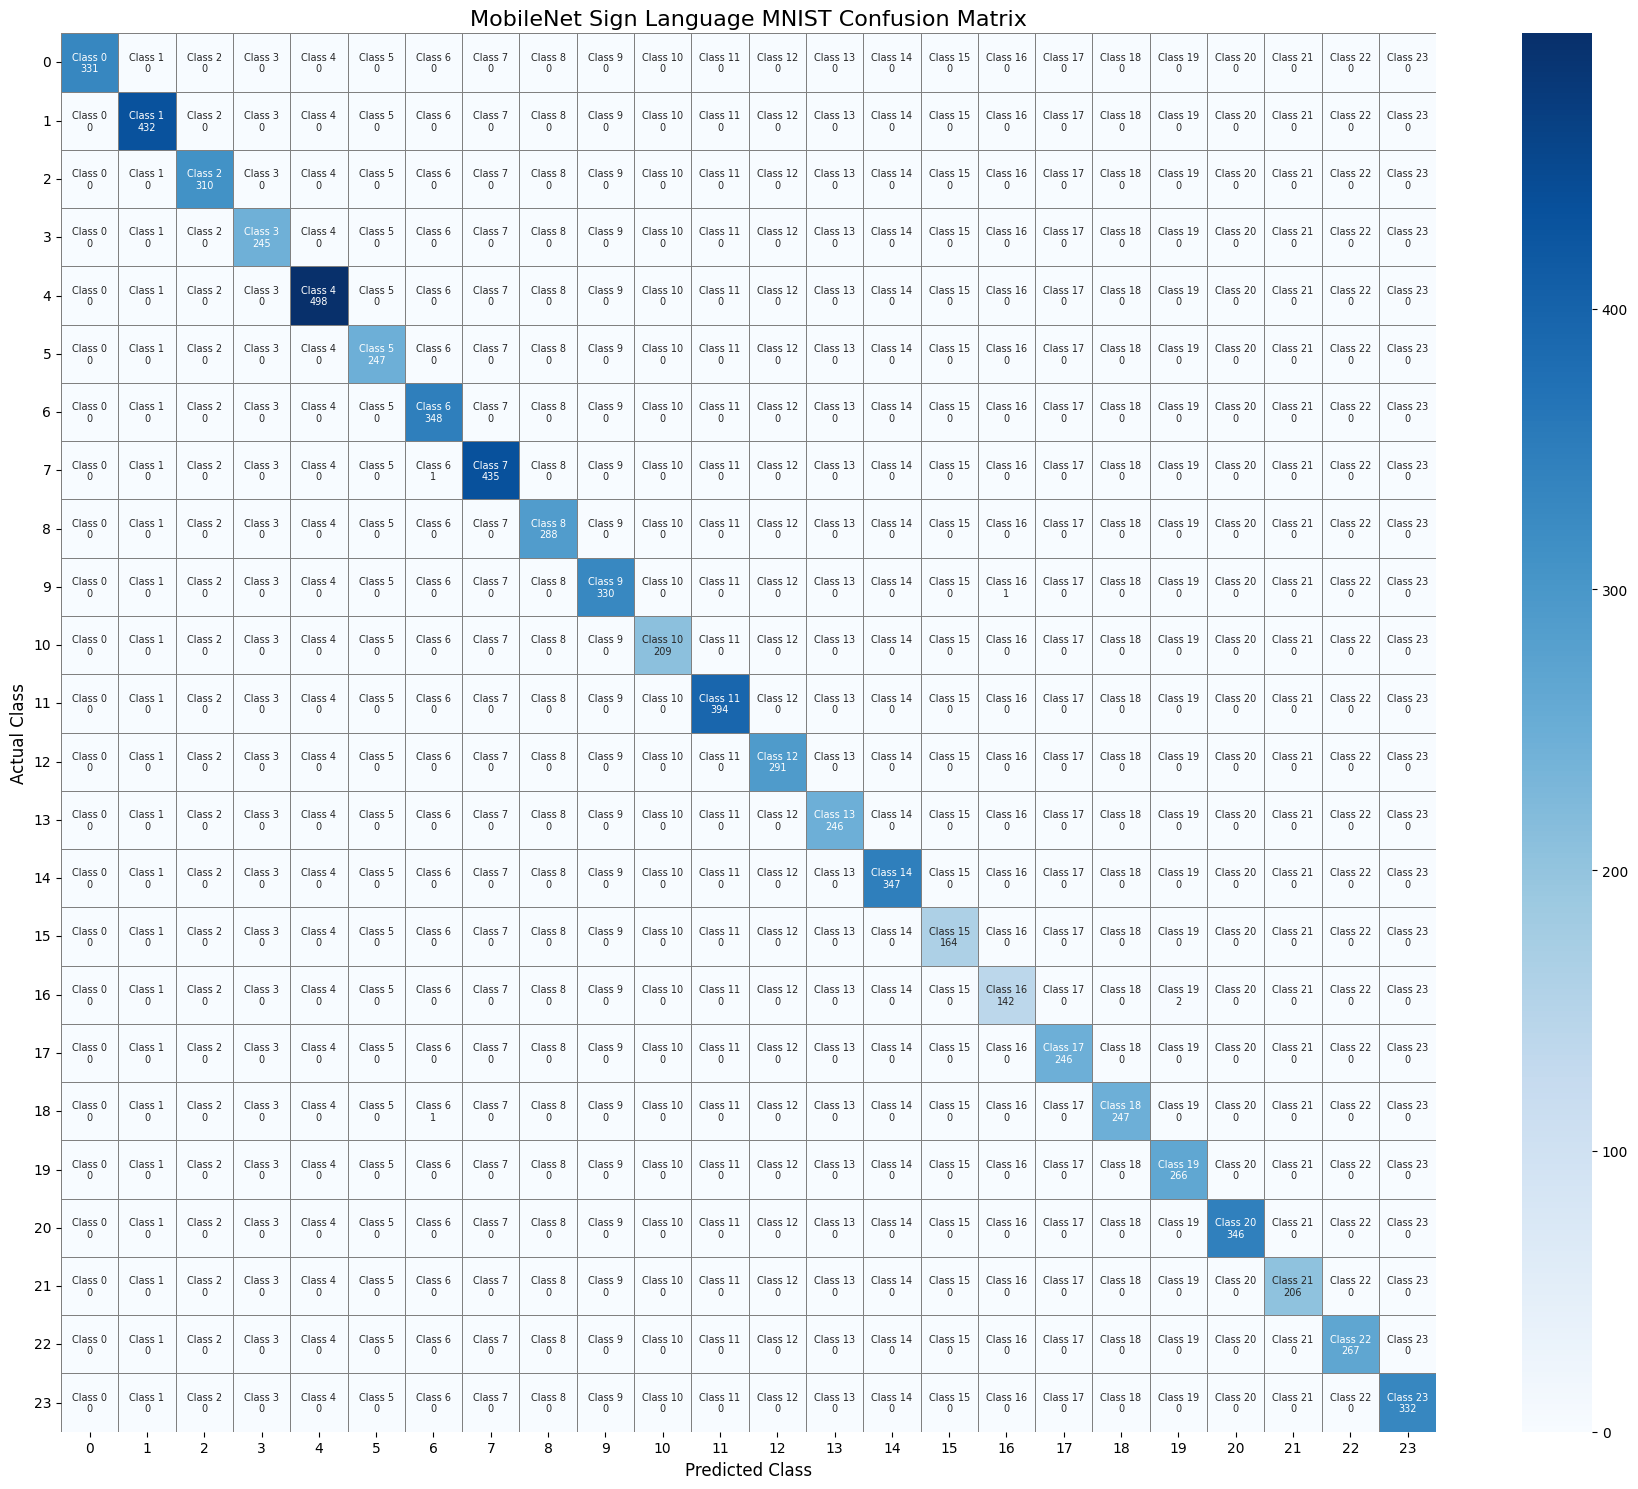

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

# Predictions using MobileNet
y_prob_mobilenet = model_mobilenet.predict(
    test_ds,
    verbose=1
)

y_pred_mobilenet = np.argmax(y_prob_mobilenet, axis=1)

# Classification report
print("MobileNet Classification Report:\n")
print(classification_report(
    y_test_encoded,
    y_pred_mobilenet,
    labels=np.arange(24),
    digits=4,
    zero_division=0
))

# Confusion matrix for all classes 0–23
classes = np.arange(24)

cm_mobilenet = confusion_matrix(
    y_test_encoded,
    y_pred_mobilenet,
    labels=classes
)

# Display predicted class and count inside each square
annotations = np.empty_like(cm_mobilenet, dtype=object)

for i in range(cm_mobilenet.shape[0]):
    for j in range(cm_mobilenet.shape[1]):
        annotations[i, j] = f"Class {j}\n{cm_mobilenet[i, j]}"

# Plot confusion matrix
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm_mobilenet,
    annot=annotations,
    fmt="",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    linewidths=0.5,
    linecolor="gray",
    annot_kws={"size": 7}
)

plt.title("MobileNet Sign Language MNIST Confusion Matrix", fontsize=16)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()